# Comprensión y preparación de datos: Telco Customer Churn

**Herramientas de Ciencias de Datos · Proyecto integrador · Hito 1**
**Fases CRISP-DM:** comprensión de los datos y preparación de los datos.

Este cuaderno continúa el de carga de datos (`01_carga_datos.ipynb`). Se ejecuta de inicio a fin en Google Colab, sin pasos manuales.

- **Fuente:** Kaggle, Telco Customer Churn (BlastChar). Enlace: https://www.kaggle.com/datasets/blastchar/telco-customer-churn
- **Fecha de obtención:** 22/10/2026
- **Archivo:** `data/WA_Fn-UseC_-Telco-Customer-Churn.csv`
- **Pregunta analítica (de la ficha):** ¿qué clientes tienen más probabilidad de darse de baja?
- **Unidad de análisis:** un cliente por fila. **Variable objetivo:** `Churn`.

**Qué hace este cuaderno**

1. *Comprensión:* revisa que los datos coincidan con el diccionario, mide su calidad, mira la variable objetivo y busca qué características se asocian con la baja.
2. *Preparación:* limpia `TotalCharges`, convierte respuestas de texto en números, crea variables nuevas, separa entrenamiento y prueba, y guarda los datos listos para modelar.

**Qué guarda:** `data/processed/telco_limpio.csv`, `data/processed/train_preparado.csv`, `data/processed/test_preparado.csv` y cinco gráficos en `figuras/`.

In [2]:
# 1. Preparación del entorno
import os
import random
import hashlib
import subprocess
import textwrap
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.stats import chi2_contingency
from sklearn.model_selection import train_test_split
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

try:
    from IPython.display import display
except ImportError:
    display = print

# Semilla fija para que los resultados sean siempre los mismos
SEMILLA = 42
random.seed(SEMILLA)
np.random.seed(SEMILLA)

# Formato de tablas y gráficos
pd.set_option("display.max_columns", 50)
pd.set_option("display.float_format", lambda x: f"{x:,.2f}")
sns.set_theme(style="whitegrid")

# Enlace del repositorio de GitHub
REPO_URL = "https://github.com/sofiaenma14/churn-telecom-proyecto-integrador.git"
CARPETA_REPO = REPO_URL.rstrip("/").split("/")[-1].replace(".git", "")

# Saber si se está ejecutando en Google Colab
try:
    import google.colab
    EN_COLAB = True
except ImportError:
    EN_COLAB = False

# En Colab se descarga el repositorio y se entra a su carpeta
if EN_COLAB and not os.path.exists("data"):
    if "USUARIO" in REPO_URL:
        raise ValueError("Falta pegar el enlace real del repositorio en REPO_URL.")
    if not os.path.exists(CARPETA_REPO):
        subprocess.run(["git", "clone", REPO_URL], check=True)
    os.chdir(CARPETA_REPO)

# Si el cuaderno se abre desde la carpeta notebooks/, se sube a la raíz del repositorio
if not os.path.exists("data") and os.path.exists("../data"):
    os.chdir("..")

# Carpetas donde se guardan los resultados de este cuaderno
os.makedirs("data/processed", exist_ok=True)
os.makedirs("figuras", exist_ok=True)
print("Carpeta de trabajo:", os.getcwd())

Carpeta de trabajo: /content/churn-telecom-proyecto-integrador


---
## Comprensión de los datos

Antes de limpiar nada hay que saber qué tenemos. Primero se confirma que el archivo es el correcto y que lo que trae coincide con el diccionario de datos.

### Estructura y validación contra el diccionario

Primero se carga el archivo comprobando su código SHA256. La tabla muestra el tipo de cada columna. El cuaderno comprueba por código que cada columna tenga exactamente los valores que declara el diccionario; si algo no coincide, se detiene con un error.

In [3]:
# 2. Carga del archivo y comprobación de que es el correcto
RUTA_CSV = "data/WA_Fn-UseC_-Telco-Customer-Churn.csv"
SHA256_ESPERADO = "88be4b93fbe0cc83421af1c503794c97c342eca914c1576db7c276e61d61358a"

with open(RUTA_CSV, "rb") as f:
    sha256_actual = hashlib.sha256(f.read()).hexdigest()
assert sha256_actual == SHA256_ESPERADO, "El archivo cambió: descárgalo otra vez de Kaggle."

df = pd.read_csv(RUTA_CSV)
assert df.shape == (7043, 21), "El tamaño no coincide con el diccionario de datos."
print("Archivo verificado. Filas y columnas:", df.shape)

Archivo verificado. Filas y columnas: (7043, 21)


In [4]:
# 3. Estructura del dataset: tipos, distintos y primeras filas
resumen = pd.DataFrame({
    "tipo": df.dtypes.astype(str),
    "nulos": df.isna().sum(),
    "valores_distintos": df.nunique(),
    "ejemplo": df.iloc[0],
})
display(resumen)
display(df.head())

,tipo,nulos,valores_distintos,ejemplo
customerID,object,0,7043,7590-VHVEG
gender,object,0,2,Female
SeniorCitizen,int64,0,2,0
Partner,object,0,2,Yes
Dependents,object,0,2,No
tenure,int64,0,73,1
PhoneService,object,0,2,No
MultipleLines,object,0,3,No phone service
InternetService,object,0,3,DSL
OnlineSecurity,object,0,3,No


,customerID,gender,SeniorCitizen,Partner,Dependents,tenure,PhoneService,MultipleLines,InternetService,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies,Contract,PaperlessBilling,PaymentMethod,MonthlyCharges,TotalCharges,Churn
0,7590-VHVEG,Female,0,Yes,No,1,No,No phone service,DSL,No,Yes,No,No,No,No,Month-to-month,Yes,Electronic check,29.85,29.85,No
1,5575-GNVDE,Male,0,No,No,34,Yes,No,DSL,Yes,No,Yes,No,No,No,One year,No,Mailed check,56.95,1889.5,No
2,3668-QPYBK,Male,0,No,No,2,Yes,No,DSL,Yes,Yes,No,No,No,No,Month-to-month,Yes,Mailed check,53.85,108.15,Yes
3,7795-CFOCW,Male,0,No,No,45,No,No phone service,DSL,Yes,No,Yes,Yes,No,No,One year,No,Bank transfer (automatic),42.30,1840.75,No
4,9237-HQITU,Female,0,No,No,2,Yes,No,Fiber optic,No,No,No,No,No,No,Month-to-month,Yes,Electronic check,70.70,151.65,Yes


In [5]:
# 4. Validación contra el diccionario de datos
SERV_INTERNET = ["OnlineSecurity", "OnlineBackup", "DeviceProtection",
                 "TechSupport", "StreamingTV", "StreamingMovies"]

VALORES_ESPERADOS = {
    "gender": {"Male", "Female"},
    "SeniorCitizen": {0, 1},
    "Partner": {"Yes", "No"},
    "Dependents": {"Yes", "No"},
    "PhoneService": {"Yes", "No"},
    "MultipleLines": {"Yes", "No", "No phone service"},
    "InternetService": {"Fiber optic", "DSL", "No"},
    "Contract": {"Month-to-month", "One year", "Two year"},
    "PaperlessBilling": {"Yes", "No"},
    "PaymentMethod": {"Electronic check", "Mailed check",
                      "Bank transfer (automatic)", "Credit card (automatic)"},
    "Churn": {"Yes", "No"},
}
for c in SERV_INTERNET:
    VALORES_ESPERADOS[c] = {"Yes", "No", "No internet service"}

# Conteos que declara el diccionario para la variable objetivo
CONTEO_CHURN_ESPERADO = {"No": 5174, "Yes": 1869}

for col, esperado in VALORES_ESPERADOS.items():
    encontrado = set(df[col].unique())
    assert encontrado == esperado, f"{col}: valores distintos a los del diccionario -> {encontrado ^ esperado}"
assert df["Churn"].value_counts().to_dict() == CONTEO_CHURN_ESPERADO
assert df["tenure"].between(0, 72).all()
assert df["MonthlyCharges"].between(18.25, 118.75).all()
print("Todas las columnas coinciden con el diccionario de datos.")

Todas las columnas coinciden con el diccionario de datos.


### Calidad de los datos

Se buscan cuatro problemas típicos: nulos, celdas que parecen llenas pero están en blanco, filas duplicadas e identificadores repetidos. `isna()` no ve los espacios en blanco, por eso se revisa aparte.

In [6]:
# 5. Calidad de los datos: nulos, celdas en blanco, duplicados
print("Nulos que detecta pandas:", int(df.isna().sum().sum()))

# Celdas que parecen llenas pero solo tienen espacios en blanco
cols_texto = df.select_dtypes(exclude="number").columns
en_blanco = {c: int((df[c].astype(str).str.strip() == "").sum()) for c in cols_texto}
en_blanco = {c: n for c, n in en_blanco.items() if n > 0}
print("Celdas en blanco por columna:", en_blanco)

print("Filas completas repetidas:", int(df.duplicated().sum()))
print("customerID repetidos:", int(df["customerID"].duplicated().sum()))

# ¿Quiénes son los clientes con TotalCharges en blanco?
filas_blanco = df[df["TotalCharges"].str.strip() == ""]
display(filas_blanco[["customerID", "tenure", "MonthlyCharges", "TotalCharges", "Contract", "Churn"]])
print("Todos tienen tenure = 0:", bool((filas_blanco["tenure"] == 0).all()))
print("Clientes con tenure = 0 en todo el dataset:", int((df["tenure"] == 0).sum()))

Nulos que detecta pandas: 0
Celdas en blanco por columna: {'TotalCharges': 11}
Filas completas repetidas: 0
customerID repetidos: 0


,customerID,tenure,MonthlyCharges,TotalCharges,Contract,Churn
488,4472-LVYGI,0,52.55,,Two year,No
753,3115-CZMZD,0,20.25,,Two year,No
936,5709-LVOEQ,0,80.85,,Two year,No
1082,4367-NUYAO,0,25.75,,Two year,No
1340,1371-DWPAZ,0,56.05,,Two year,No
3331,7644-OMVMY,0,19.85,,Two year,No
3826,3213-VVOLG,0,25.35,,Two year,No
4380,2520-SGTTA,0,20.00,,Two year,No
5218,2923-ARZLG,0,19.70,,One year,No
6670,4075-WKNIU,0,73.35,,Two year,No


Todos tienen tenure = 0: True
Clientes con tenure = 0 en todo el dataset: 11


### Variable objetivo

Se mide cuántos clientes se dieron de baja. Ese porcentaje es la **línea base** del KPI de la ficha. También sirve para saber si las clases están muy desbalanceadas.

,clientes,porcentaje
Churn,,
No,5174,73.46
Yes,1869,26.54


Línea base (tasa de fuga): 26.54%


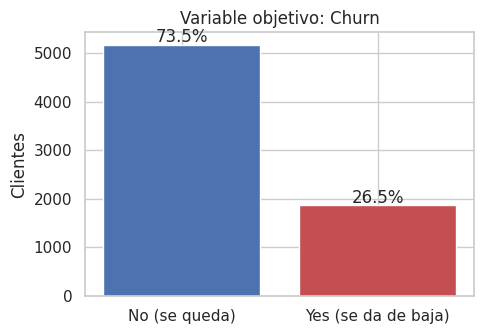

In [7]:
# 6. Variable objetivo: Churn
conteo = df["Churn"].value_counts()
porcentaje = df["Churn"].value_counts(normalize=True) * 100
display(pd.DataFrame({"clientes": conteo, "porcentaje": porcentaje}))

linea_base = (df["Churn"] == "Yes").mean() * 100
print(f"Línea base (tasa de fuga): {linea_base:.2f}%")

fig, ax = plt.subplots(figsize=(5, 3.5))
barras = ax.bar(["No (se queda)", "Yes (se da de baja)"], [conteo["No"], conteo["Yes"]],
                color=["#4C72B0", "#C44E52"])
for b, p in zip(barras, [porcentaje["No"], porcentaje["Yes"]]):
    ax.text(b.get_x() + b.get_width() / 2, b.get_height() + 50, f"{p:.1f}%", ha="center")
ax.set_ylabel("Clientes")
ax.set_title("Variable objetivo: Churn")
plt.tight_layout()
plt.savefig("figuras/01_churn_distribucion.png", dpi=150)
plt.show()

### Variables numéricas

`tenure` (meses), `MonthlyCharges` y `TotalCharges`. Para explorar, `TotalCharges` se convierte a número en una copia (`df_exp`), sin modificar `df`. Los histogramas comparan a quienes se quedan con quienes se van.

,count,mean,std,min,25%,50%,75%,max
tenure,"7,043.00",32.37,24.56,0.00,9.00,29.00,55.00,72.00
MonthlyCharges,"7,043.00",64.76,30.09,18.25,35.50,70.35,89.85,118.75
TotalCharges,"7,032.00","2,283.30","2,266.77",18.80,401.45,"1,397.47","3,794.74","8,684.80"


,variable,atipicos_IQR
0,tenure,0
1,MonthlyCharges,0
2,TotalCharges,0


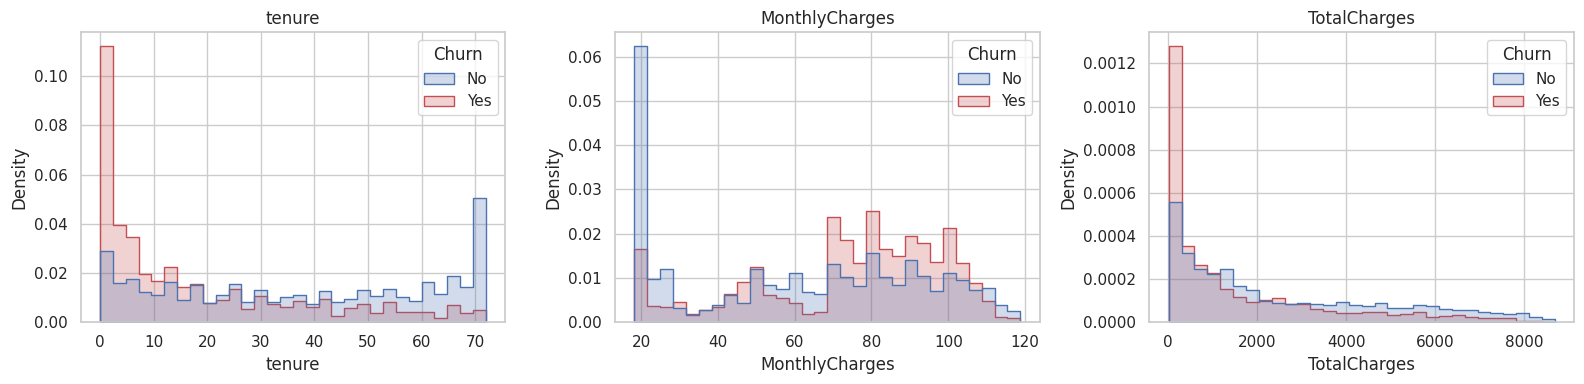

,tenure,MonthlyCharges,TotalCharges
Churn,,,
No (se queda),38.00,64.43,"1,683.60"
Yes (se da de baja),10.00,79.65,703.55


In [8]:
# 7. Variables numéricas (TotalCharges se pasa a número sin tocar df)
df_exp = df.copy()
df_exp["TotalCharges"] = pd.to_numeric(df_exp["TotalCharges"].str.strip(), errors="coerce")
NUMERICAS = ["tenure", "MonthlyCharges", "TotalCharges"]

display(df_exp[NUMERICAS].describe().T)

# Valores atípicos con la regla del rango intercuartílico
filas = []
for c in NUMERICAS:
    q1, q3 = df_exp[c].quantile([0.25, 0.75])
    iqr = q3 - q1
    n_atip = int(((df_exp[c] < q1 - 1.5 * iqr) | (df_exp[c] > q3 + 1.5 * iqr)).sum())
    filas.append({"variable": c, "atipicos_IQR": n_atip})
display(pd.DataFrame(filas))

fig, axes = plt.subplots(1, 3, figsize=(16, 4))
for ax, c in zip(axes, NUMERICAS):
    sns.histplot(data=df_exp, x=c, hue="Churn", bins=30, element="step",
                 stat="density", common_norm=False,
                 palette={"No": "#4C72B0", "Yes": "#C44E52"}, ax=ax)
    ax.set_title(c)
plt.tight_layout()
plt.savefig("figuras/02_numericas_por_churn.png", dpi=150)
plt.show()

display(df_exp.groupby("Churn")[NUMERICAS].median().rename(index={"No": "No (se queda)", "Yes": "Yes (se da de baja)"}))

### Variables categóricas frente a la baja

Para cada valor de cada columna se calcula la **tasa de fuga** (clientes que se dieron de baja / clientes del grupo × 100) y se compara con la línea base de 26.54%. Un grupo por encima de la línea tiene más riesgo que el cliente promedio.

Los 8 grupos con más fuga:


,variable,valor,clientes,bajas,tasa_fuga_%
41,PaymentMethod,Electronic check,2365,1071,45.29
34,Contract,Month-to-month,3875,1655,42.71
14,InternetService,Fiber optic,3096,1297,41.89
16,OnlineSecurity,No,3498,1461,41.77
3,SeniorCitizen,1,1142,476,41.68
25,TechSupport,No,3473,1446,41.64
19,OnlineBackup,No,3088,1233,39.93
22,DeviceProtection,No,3095,1211,39.13


Los 8 grupos con menos fuga (se omite 'No internet service': es el mismo grupo que InternetService = No):


,variable,valor,clientes,bajas,tasa_fuga_%
36,Contract,Two year,1695,48,2.83
15,InternetService,No,1526,113,7.40
35,Contract,One year,1473,166,11.27
18,OnlineSecurity,Yes,2019,295,14.61
27,TechSupport,Yes,2044,310,15.17
40,PaymentMethod,Credit card (automatic),1522,232,15.24
7,Dependents,Yes,2110,326,15.45
37,PaperlessBilling,No,2872,469,16.33


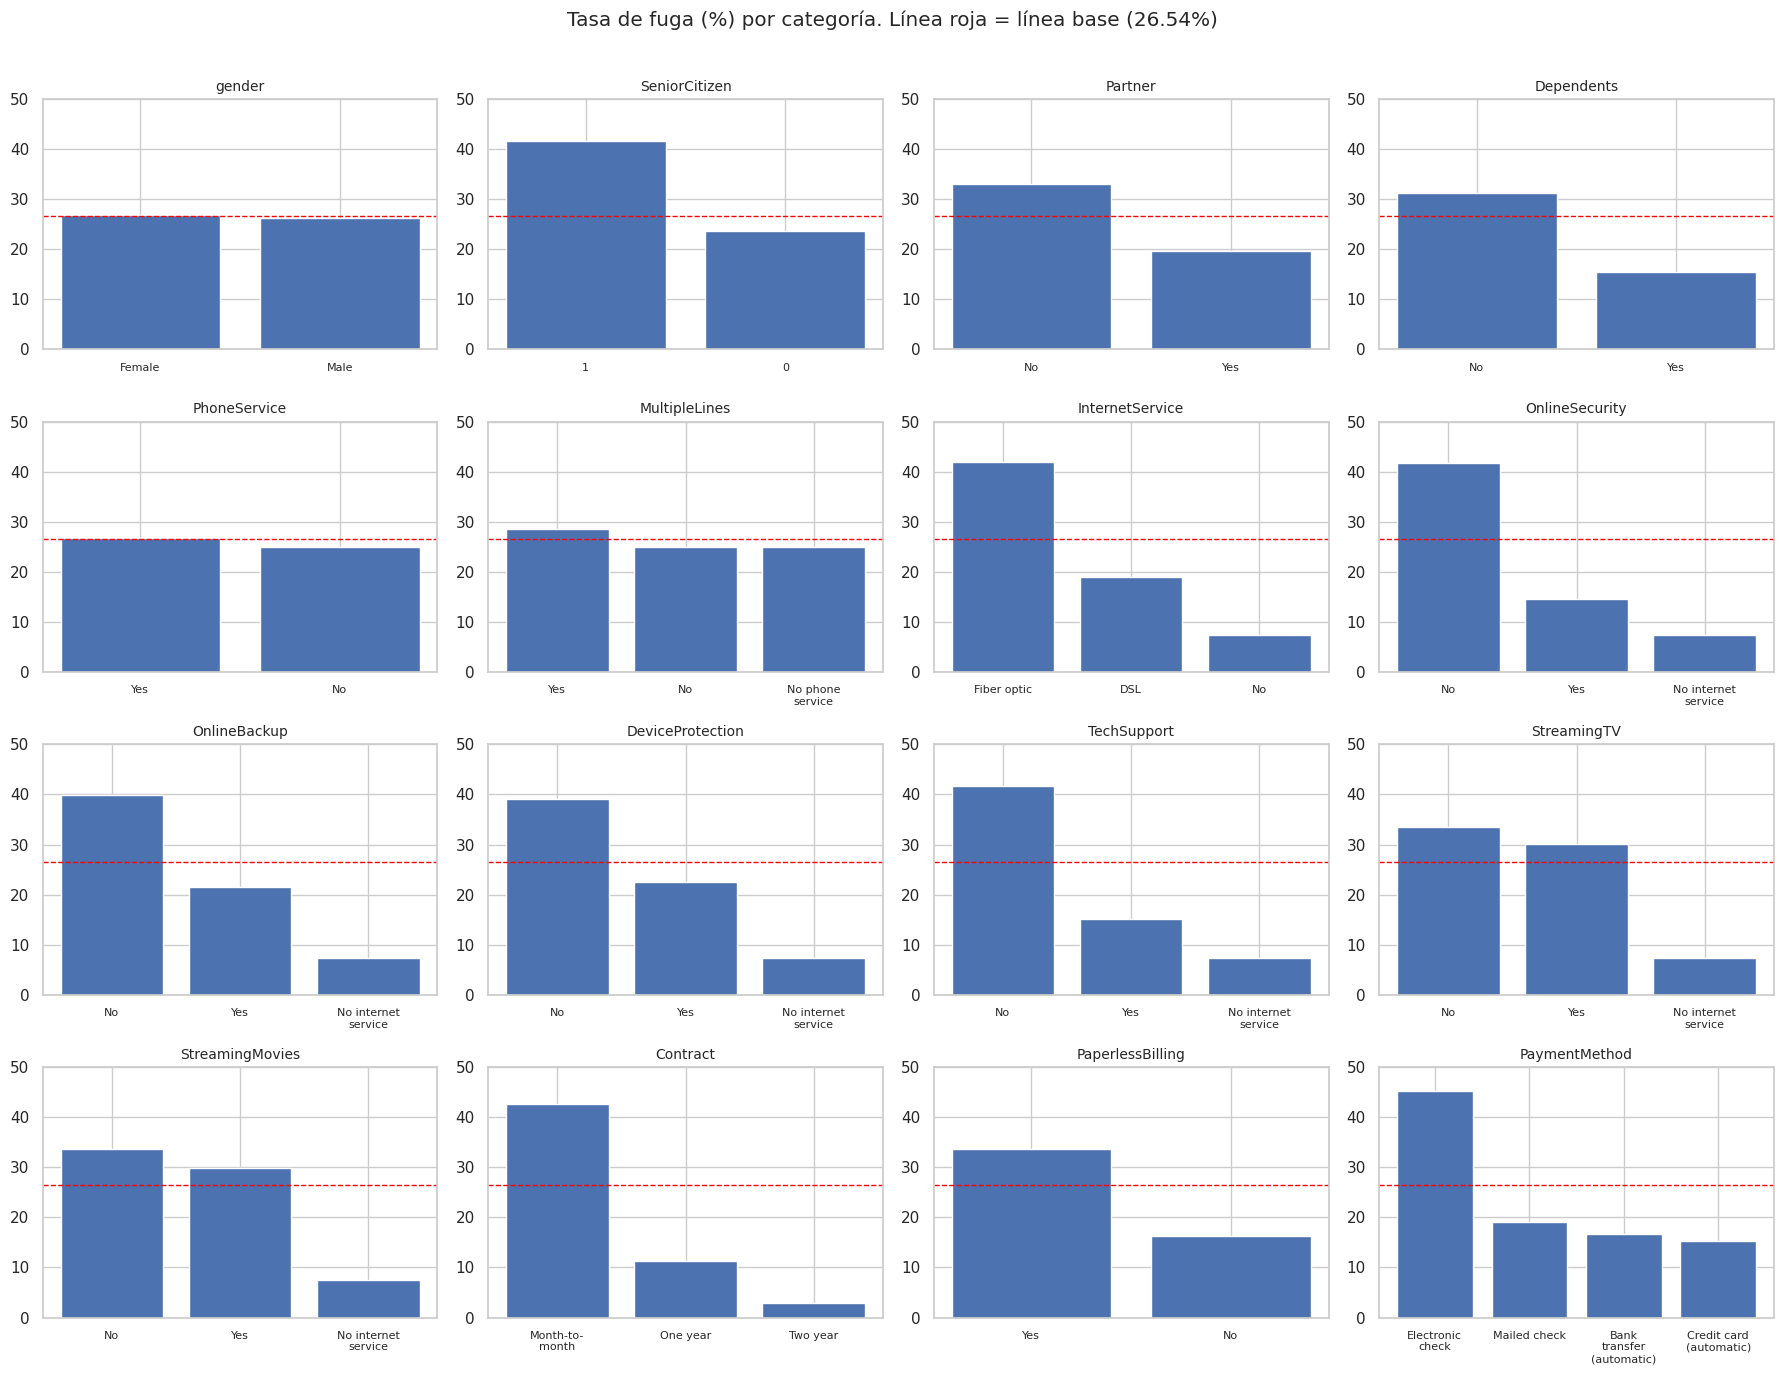

In [9]:
# 8. Variables categóricas frente a Churn: tasa de fuga por cada valor
CAT_COLS = [c for c in df.columns if c not in ["customerID", "Churn", "tenure", "MonthlyCharges", "TotalCharges"]]

tablas = []
for c in CAT_COLS:
    g = df.groupby(c)["Churn"].agg(clientes="size", bajas=lambda s: int((s == "Yes").sum()))
    g["tasa_fuga_%"] = g["bajas"] / g["clientes"] * 100
    g = g.reset_index().rename(columns={c: "valor"})
    g.insert(0, "variable", c)
    tablas.append(g)
tabla_cat = pd.concat(tablas, ignore_index=True)
tabla_cat["valor"] = tabla_cat["valor"].astype(str)

print("Los 8 grupos con más fuga:")
display(tabla_cat.sort_values("tasa_fuga_%", ascending=False).head(8))
print("Los 8 grupos con menos fuga (se omite 'No internet service': es el mismo grupo que InternetService = No):")
display(tabla_cat[tabla_cat["valor"] != "No internet service"].sort_values("tasa_fuga_%").head(8))

fig, axes = plt.subplots(4, 4, figsize=(18, 14))
for ax, c in zip(axes.ravel(), CAT_COLS):
    t = tabla_cat[tabla_cat["variable"] == c].sort_values("tasa_fuga_%", ascending=False)
    ax.bar(range(len(t)), t["tasa_fuga_%"], color="#4C72B0")
    ax.set_xticks(range(len(t)))
    ax.set_xticklabels([textwrap.fill(v, 12) for v in t["valor"]], fontsize=8)
    ax.axhline(linea_base, color="red", ls="--", lw=1)
    ax.set_title(c, fontsize=10)
    ax.set_ylim(0, 50)
fig.suptitle("Tasa de fuga (%) por categoría. Línea roja = línea base (26.54%)")
plt.tight_layout(rect=[0, 0, 1, 0.97])
plt.savefig("figuras/03_tasa_fuga_por_categoria.png", dpi=150)
plt.show()

### Antigüedad

`tenure` es una de las señales más fuertes. Se agrupa en cuatro tramos para ver cuándo se van los clientes. Estos mismos tramos se usarán después para crear la variable `grupo_antiguedad`.

,clientes,bajas,tasa_fuga_%
tenure,,,
0-12 meses,2186,1037,47.44
13-24 meses,1024,294,28.71
25-48 meses,1594,325,20.39
49-72 meses,2239,213,9.51


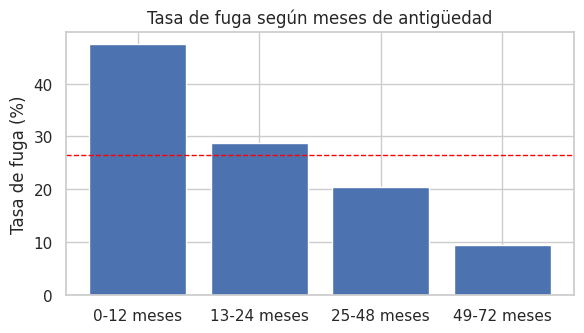

In [10]:
# 9. Antigüedad (tenure) y fuga: ¿en qué momento se van los clientes?
tramos = pd.cut(df["tenure"], bins=[-1, 12, 24, 48, 72],
                labels=["0-12 meses", "13-24 meses", "25-48 meses", "49-72 meses"])
por_tramo = df.groupby(tramos, observed=True)["Churn"].agg(
    clientes="size", bajas=lambda s: int((s == "Yes").sum()))
por_tramo["tasa_fuga_%"] = por_tramo["bajas"] / por_tramo["clientes"] * 100
display(por_tramo)

fig, ax = plt.subplots(figsize=(6, 3.5))
ax.bar(por_tramo.index.astype(str), por_tramo["tasa_fuga_%"], color="#4C72B0")
ax.axhline(linea_base, color="red", ls="--", lw=1)
ax.set_ylabel("Tasa de fuga (%)")
ax.set_title("Tasa de fuga según meses de antigüedad")
plt.tight_layout()
plt.savefig("figuras/04_fuga_por_antiguedad.png", dpi=150)
plt.show()

### Coherencia entre columnas

Se verifica que los datos no se contradigan: que `No internet service` y `No phone service` aparezcan solo cuando corresponde, y qué tanto se parece `TotalCharges` a `tenure × MonthlyCharges`.

In [11]:
# 10. Coherencia entre columnas
# "No internet service" aparece solo cuando InternetService = No
sin_internet = df["InternetService"] == "No"
ok_internet = ((df.loc[sin_internet, SERV_INTERNET] == "No internet service").all().all()
               and not (df.loc[~sin_internet, SERV_INTERNET] == "No internet service").any().any())
print("Servicios de internet coherentes con InternetService:", bool(ok_internet))

# "No phone service" aparece solo cuando PhoneService = No
sin_telefono = df["PhoneService"] == "No"
ok_tel = ((df.loc[sin_telefono, "MultipleLines"] == "No phone service").all()
          and not (df.loc[~sin_telefono, "MultipleLines"] == "No phone service").any())
print("MultipleLines coherente con PhoneService:", bool(ok_tel))

# TotalCharges debería parecerse a tenure x MonthlyCharges
esperado = df_exp["tenure"] * df_exp["MonthlyCharges"]
con_dato = esperado > 0
dif_rel = ((df_exp["TotalCharges"] - esperado)[con_dato] / esperado[con_dato]).abs()
print(f"Correlación TotalCharges vs tenure x MonthlyCharges: {df_exp.loc[con_dato, 'TotalCharges'].corr(esperado[con_dato]):.3f}")
print(f"Mediana de la diferencia relativa: {dif_rel.median()*100:.1f}%")
print(f"Clientes con diferencia mayor al 20%: {int((dif_rel > 0.20).sum())} de {int(con_dato.sum())}")

Servicios de internet coherentes con InternetService: True
MultipleLines coherente con PhoneService: True
Correlación TotalCharges vs tenure x MonthlyCharges: 1.000
Mediana de la diferencia relativa: 2.0%
Clientes con diferencia mayor al 20%: 59 de 7032


### Asociación con la baja

- **V de Cramér** mide qué tan fuerte se relaciona una variable categórica con `Churn` (0 = nada, 1 = total).
- Para las numéricas se usa la correlación con `Churn` (1 = baja).

Es una guía para entender los datos, **no** una prueba de causa: que dos cosas vayan juntas no significa que una provoque la otra.

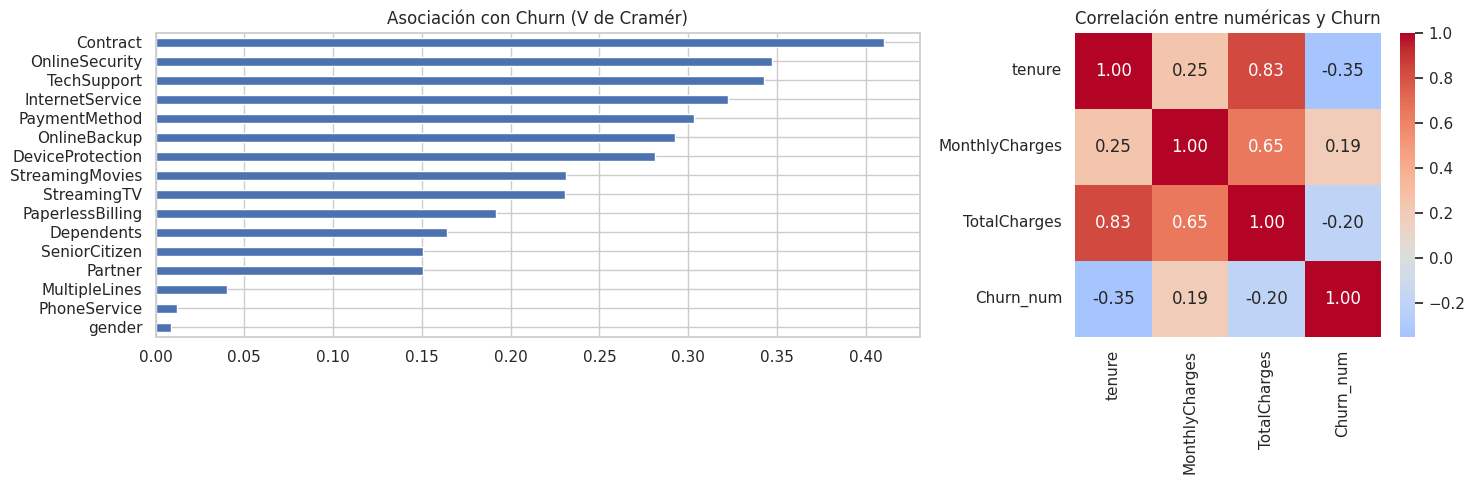

Top 5 variables categóricas más asociadas a Churn:


,V_de_Cramér
Contract,0.41
OnlineSecurity,0.35
TechSupport,0.34
InternetService,0.32
PaymentMethod,0.30


In [12]:
# 11. ¿Qué variables se asocian más con Churn?
def cramer_v(x, y):
    """Fuerza de asociación entre dos variables categóricas (0 = ninguna, 1 = total)."""
    tabla = pd.crosstab(x, y)
    chi2 = chi2_contingency(tabla, correction=False)[0]
    return float(np.sqrt(chi2 / (tabla.values.sum() * (min(tabla.shape) - 1))))

v_cramer = pd.Series({c: cramer_v(df[c], df["Churn"]) for c in CAT_COLS}).sort_values(ascending=False)

# Variables numéricas: correlación con Churn (1 = baja)
df_exp["Churn_num"] = (df_exp["Churn"] == "Yes").astype(int)
corr_num = df_exp[NUMERICAS + ["Churn_num"]].corr()

fig, axes = plt.subplots(1, 2, figsize=(15, 5), gridspec_kw={"width_ratios": [2, 1]})
v_cramer.sort_values().plot.barh(ax=axes[0], color="#4C72B0")
axes[0].set_title("Asociación con Churn (V de Cramér)")
sns.heatmap(corr_num, annot=True, fmt=".2f", cmap="coolwarm", center=0, ax=axes[1])
axes[1].set_title("Correlación entre numéricas y Churn")
plt.tight_layout()
plt.savefig("figuras/05_asociacion_con_churn.png", dpi=150)
plt.show()

print("Top 5 variables categóricas más asociadas a Churn:")
display(v_cramer.head(5).to_frame("V_de_Cramér"))

---
## Preparación de los datos

Se trabaja sobre una copia (`df_limpio`) para no perder los datos originales. Cada paso tiene su justificación, y al final hay verificaciones automáticas.

### Limpieza de `TotalCharges`

Los 11 espacios en blanco son clientes con `tenure = 0`: todavía no pagan nada. Por eso se rellenan con **0** y no con la media o la mediana, que les inventarían un gasto que no existe. El `assert` comprueba que esa explicación se cumple en los 11 casos.

In [13]:
# 12. Limpieza: TotalCharges pasa a número y los 11 espacios en blanco se resuelven
df_limpio = df.copy()

df_limpio["TotalCharges"] = pd.to_numeric(df_limpio["TotalCharges"].str.strip(), errors="coerce")
faltantes = df_limpio["TotalCharges"].isna()
print("TotalCharges faltantes:", int(faltantes.sum()))

# Decisión: son clientes con tenure = 0 que aún no reciben su primera factura,
# así que lo que han pagado hasta ahora es 0
assert (df_limpio.loc[faltantes, "tenure"] == 0).all()
df_limpio.loc[faltantes, "TotalCharges"] = 0.0

assert df_limpio["TotalCharges"].notna().all()
print("TotalCharges ahora es:", df_limpio["TotalCharges"].dtype)

TotalCharges faltantes: 11
TotalCharges ahora es: float64


### Codificación de respuestas de texto

Los modelos necesitan números. Las columnas de sí o no pasan a 1 o 0, igual que `Churn` (1 = se dio de baja). En los servicios de internet y en `MultipleLines`, los valores `No internet service` y `No phone service` pasan a 0 porque esa información ya está en `InternetService` y `PhoneService`: no se pierde nada y se evita repetir.

In [14]:
# 13. Codificación: las respuestas de texto pasan a números (1 = Yes, 0 = No)
df_limpio["Churn"] = (df_limpio["Churn"] == "Yes").astype(int)

COLS_SI_NO = ["Partner", "Dependents", "PhoneService", "PaperlessBilling"]
for c in COLS_SI_NO + SERV_INTERNET + ["MultipleLines"]:
    # "No internet service" y "No phone service" pasan a 0: esa información no se pierde, porque ya está en InternetService y PhoneService
    df_limpio[c] = (df_limpio[c] == "Yes").astype(int)

print("Churn (0 = se queda, 1 = se da de baja):")
print(df_limpio["Churn"].value_counts().sort_index())
display(df_limpio[COLS_SI_NO + ["MultipleLines"] + SERV_INTERNET].head())

Churn (0 = se queda, 1 = se da de baja):
Churn
0    5174
1    1869
Name: count, dtype: int64


,Partner,Dependents,PhoneService,PaperlessBilling,MultipleLines,OnlineSecurity,OnlineBackup,DeviceProtection,TechSupport,StreamingTV,StreamingMovies
0,1,0,0,1,0,0,1,0,0,0,0
1,0,0,1,0,0,1,0,1,0,0,0
2,0,0,1,1,0,1,1,0,0,0,0
3,0,0,0,0,0,1,0,1,1,0,0
4,0,0,1,1,0,0,0,0,0,0,0


### Variables nuevas


| Variable | Qué es | Por qué |
|---|---|---|
| `n_servicios` | Cuántos servicios tiene el cliente (0 a 9) | Resume el nivel de vinculación con la empresa |
| `grupo_antiguedad` | Tramo de `tenure` (0-12, 13-24, 25-48, 49-72 meses) | La fuga cae por tramos, no de forma pareja |
| `pago_automatico` | 1 si paga con transferencia o tarjeta automática | Los pagos automáticos tienen mucha menos fuga que el cheque electrónico |

La tabla de abajo muestra que la fuga **no sube ni baja de forma pareja** con `n_servicios` (el pico está en 3 servicios). Es una razón para no asumir relaciones simples.

In [15]:
# 14. Variables nuevas a partir de las que ya hay
# Cuántos servicios tiene contratados cada cliente (de 0 a 9)
df_limpio["n_servicios"] = (df_limpio["PhoneService"]
                            + df_limpio["MultipleLines"]
                            + (df_limpio["InternetService"] != "No").astype(int)
                            + df_limpio[SERV_INTERNET].sum(axis=1))

# Grupo de antigüedad, según los tramos que se vieron en la exploración
df_limpio["grupo_antiguedad"] = pd.cut(
    df_limpio["tenure"], bins=[-1, 12, 24, 48, 72],
    labels=["0-12 meses", "13-24 meses", "25-48 meses", "49-72 meses"]).astype(str)

# Si paga con débito o cobro automático (transferencia o tarjeta)
df_limpio["pago_automatico"] = df_limpio["PaymentMethod"].str.contains("automatic").astype(int)

display(df_limpio[["tenure", "grupo_antiguedad", "n_servicios", "PaymentMethod", "pago_automatico"]].head())
display(df_limpio.groupby("n_servicios")["Churn"].agg(clientes="size", tasa_fuga="mean").assign(
    tasa_fuga=lambda t: t["tasa_fuga"] * 100).rename(columns={"tasa_fuga": "tasa_fuga_%"}))

,tenure,grupo_antiguedad,n_servicios,PaymentMethod,pago_automatico
0,1,0-12 meses,2,Electronic check,0
1,34,25-48 meses,4,Mailed check,0
2,2,0-12 meses,4,Mailed check,0
3,45,25-48 meses,4,Bank transfer (automatic),1
4,2,0-12 meses,2,Electronic check,0


,clientes,tasa_fuga_%
n_servicios,,
1,1264,10.92
2,859,30.97
3,846,44.92
4,965,36.48
5,922,31.34
6,908,25.55
7,676,22.49
8,395,12.41
9,208,5.29


### Qué entra al modelo y qué no

- `customerID` solo identifica al cliente: no se usa para modelar.
- `gender` y `SeniorCitizen` son datos personales. La ficha dice que no se usan sin una razón de negocio clara, así que se guardan solo para revisar después si el modelo trata distinto a algún grupo y no entran como variables.
- `grupo_antiguedad` y `tenure` cuentan lo mismo de dos formas. Se dejan ambas por ahora; en el modelado se puede probar cuál conviene.

In [16]:
# 15. Qué columnas entran al modelo y cuáles no
COL_ID = "customerID"                       # solo identifica al cliente: no se usa para modelar
OBJETIVO = "Churn"
COL_AUDITORIA = ["gender", "SeniorCitizen"] # datos personales: se guardan para revisar si el modelo trata distinto a algún grupo, pero NO entran como variables

NUMERICAS_MOD = ["tenure", "MonthlyCharges", "TotalCharges", "n_servicios"]
BINARIAS_MOD = ["Partner", "Dependents", "PhoneService", "MultipleLines"] + SERV_INTERNET \
               + ["PaperlessBilling", "pago_automatico"]
CATEGORICAS_MOD = ["InternetService", "Contract", "PaymentMethod", "grupo_antiguedad"]
VARIABLES_MOD = NUMERICAS_MOD + BINARIAS_MOD + CATEGORICAS_MOD

print("Variables que entran al modelo:", len(VARIABLES_MOD))
print("Columnas del dataset limpio:", df_limpio.shape[1])

# Dataset limpio, legible y sin escalar
df_limpio.to_csv("data/processed/telco_limpio.csv", index=False)
print("Guardado: data/processed/telco_limpio.csv")

Variables que entran al modelo: 20
Columnas del dataset limpio: 24
Guardado: data/processed/telco_limpio.csv


### División entrenamiento y prueba

Se separa 80% para entrenar y 20% para probar, con `stratify` para que ambos tengan 26.54% de bajas. Se divide antes de calcular medias y escalas: si el escalador viera los datos de prueba, el modelo tendría información que en la vida real no tendría .

In [18]:
# 16. División en entrenamiento y prueba (80% / 20%), manteniendo la proporción de Churn
# Se divide antes de calcular medias o escalas, para que la parte de prueba no influya en nada
train, test = train_test_split(df_limpio, test_size=0.20, stratify=df_limpio[OBJETIVO],
                               random_state=SEMILLA)

resumen_split = pd.DataFrame({
    "clientes": [len(train), len(test)],
    "tasa_fuga_%": [train[OBJETIVO].mean() * 100, test[OBJETIVO].mean() * 100],
}, index=["entrenamiento", "prueba"])
display(resumen_split)

,clientes,tasa_fuga_%
entrenamiento,5634,26.54
prueba,1409,26.54


### Escalado y variables 0/1 para las categorías

- **Escalado (`StandardScaler`)** para las numéricas: media 0 y desviación 1, así `TotalCharges` (hasta 8 684) no pesa más que `n_servicios` (hasta 9) solo por su tamaño.
- **`OneHotEncoder`** convierte categorías como `Contract` en columnas 0/1. Con `drop="first"` se elimina una columna por variable para evitar redundancia.
- Las binarias pasan tal cual.

El preprocesador **aprende solo con entrenamiento** (`fit_transform`) y se aplica a prueba con `transform`.

In [19]:
# 17. Transformaciones: escalar números y convertir categorías en columnas 0/1
# El preprocesador aprende SOLO con entrenamiento (fit) y luego se aplica a prueba (transform).
preprocesador = ColumnTransformer(
    transformers=[
        ("numericas", StandardScaler(), NUMERICAS_MOD),
        ("binarias", "passthrough", BINARIAS_MOD),
        ("categoricas", OneHotEncoder(drop="first", handle_unknown="ignore", sparse_output=False),
         CATEGORICAS_MOD),
    ],
    verbose_feature_names_out=False,
)
preprocesador.set_output(transform="pandas")

X_train = preprocesador.fit_transform(train[VARIABLES_MOD])
X_test = preprocesador.transform(test[VARIABLES_MOD])
y_train, y_test = train[OBJETIVO], test[OBJETIVO]

print("X_train:", X_train.shape, "| X_test:", X_test.shape)
print("Columnas finales:", list(X_train.columns))
print()
print("Media y desviación que aprendió el escalador (solo con entrenamiento):")
display(pd.DataFrame({"media": preprocesador.named_transformers_["numericas"].mean_,
                      "desviacion": preprocesador.named_transformers_["numericas"].scale_},
                     index=NUMERICAS_MOD))

X_train: (5634, 26) | X_test: (1409, 26)
Columnas finales: ['tenure', 'MonthlyCharges', 'TotalCharges', 'n_servicios', 'Partner', 'Dependents', 'PhoneService', 'MultipleLines', 'OnlineSecurity', 'OnlineBackup', 'DeviceProtection', 'TechSupport', 'StreamingTV', 'StreamingMovies', 'PaperlessBilling', 'pago_automatico', 'InternetService_Fiber optic', 'InternetService_No', 'Contract_One year', 'Contract_Two year', 'PaymentMethod_Credit card (automatic)', 'PaymentMethod_Electronic check', 'PaymentMethod_Mailed check', 'grupo_antiguedad_13-24 meses', 'grupo_antiguedad_25-48 meses', 'grupo_antiguedad_49-72 meses']

Media y desviación que aprendió el escalador (solo con entrenamiento):


,media,desviacion
tenure,32.49,24.57
MonthlyCharges,64.93,30.14
TotalCharges,"2,299.33","2,279.00"
n_servicios,4.17,2.32


### Verificaciones finales

Pruebas automáticas: sin nulos, objetivo solo 0 y 1, ningún cliente perdido ni repetido, ningún cliente en ambos conjuntos, misma proporción de bajas y que el escalado se aprendió solo con entrenamiento.

In [20]:
# 18. Verificaciones finales (si algo falla, el cuaderno se detiene)
assert X_train.isna().sum().sum() == 0 and X_test.isna().sum().sum() == 0, "Quedaron nulos."
assert set(y_train.unique()) <= {0, 1} and set(y_test.unique()) <= {0, 1}
assert len(train) + len(test) == len(df), "Se perdieron o se repitieron clientes."
assert set(train[COL_ID]).isdisjoint(set(test[COL_ID])), "Hay clientes en entrenamiento y en prueba."
assert abs(train[OBJETIVO].mean() - test[OBJETIVO].mean()) < 0.005, "La proporción de Churn cambió."
assert list(X_train.columns) == list(X_test.columns)
assert np.allclose(X_train[NUMERICAS_MOD].mean(), 0, atol=1e-6)   # entrenamiento queda centrado
assert not np.allclose(X_test[NUMERICAS_MOD].mean(), 0, atol=1e-6) # prueba NO se centró con sus datos
print("Todas las verificaciones pasaron.")

Todas las verificaciones pasaron.


### Guardado

`telco_limpio.csv` es la versión limpia y legible (sin escalar). `train_preparado.csv` y `test_preparado.csv` ya están listos para el modelo y llevan además `customerID`, `Churn` y las columnas `aud_*` para la revisión de sesgos.

In [ ]:
# 19. Guardar los datos preparados (los usará el cuaderno de modelado)
def guardar(X, y, base, ruta):
    salida = X.copy()
    salida.insert(0, COL_ID, base[COL_ID].values)
    salida[OBJETIVO] = y.values
    # Columnas para revisar sesgos después (no son variables del modelo)
    for c in COL_AUDITORIA:
        salida["aud_" + c] = base[c].values
    salida.to_csv(ruta, index=False)

guardar(X_train, y_train, train, "data/processed/train_preparado.csv")
guardar(X_test, y_test, test, "data/processed/test_preparado.csv")

for nombre in sorted(os.listdir("data/processed")):
    print(f"{nombre:28s} {os.path.getsize('data/processed/' + nombre) / 1024:8.1f} KB")